# Olist: acquisition funnel and customer satisfaction

**Business question.** Where should a Brazilian e-commerce marketplace invest to grow: in *which acquisition channels* it recruits sellers from, and in *which parts of the customer experience* it fixes first?

**Data.** Two public Olist datasets from Kaggle: the *Brazilian E-Commerce Public Dataset* (about 100k orders, 2016-2018, 9 tables) and the *Marketing Funnel* dataset (8,000 qualified leads, 842 closed deals). They are loaded into a SQLite database (`src/build_db.py`) and analysed with SQL (`sql/queries/`) plus Python.

**How the work is split.** SQL does the heavy lifting (joins, CTEs, window functions) and lives in `sql/`. Python, in this notebook, adds what SQL is bad at: confidence intervals, a significance test, clustering and the charts.

1. **Part A: acquisition funnel.** Channel conversion, seller revenue concentration, landing pages.
2. **Part B: customers and satisfaction.** Delivery delays vs reviews, states, monthly trend, repeat purchase.
3. **Part C: customer segmentation** with K-means.
4. **Recommendations and limitations.**

In [1]:
import math
import sqlite3
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter, PercentFormatter
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT / "src"))
from run_queries import parse  # reads the named queries from the .sql files

con = sqlite3.connect(ROOT / "data" / "olist.db")
QUERIES = {**parse(ROOT / "sql/queries/03_funnel.sql"),
           **parse(ROOT / "sql/queries/04_customers.sql")}


def sql(name: str) -> pd.DataFrame:
    """Run one of the named queries from sql/queries/."""
    return pd.read_sql_query(QUERIES[name], con)


def wilson(k, n, z=1.96):
    """95% Wilson score interval for a proportion k/n."""
    p = k / n
    d = 1 + z * z / n
    centre = (p + z * z / (2 * n)) / d
    half = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return centre - half, centre + half


# --- chart style: one validated palette, fixed order (blue, orange, aqua, yellow)
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
SURFACE, GRID, AXIS, GREY = "#fcfcfb", "#e1e0d9", "#c3c2b7", "#b5b3ab"
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": AXIS, "axes.grid": False,
})
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)


def style(ax, grid=None):
    ax.tick_params(length=0)
    if grid:
        ax.grid(axis=grid, color=GRID, linewidth=0.8)
        ax.set_axisbelow(True)


def headline(fig, head, sub, top=0.97):
    fig.text(0.01, top, head, ha="left", va="top", fontsize=14, fontweight="bold", color=INK)
    fig.text(0.01, top - 0.075, sub, ha="left", va="top", fontsize=10, color=INK2)


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")


pd.options.display.float_format = "{:,.2f}".format
pd.options.display.width = 160

## Data notes that shape the analysis

Profiling the 11 CSVs (see `sql/01_schema.sql` and `src/build_db.py`) showed four things that matter for every result below:

- **Customers.** `customer_id` changes on every order; the person is `customer_unique_id`. Only **3%** of customers ever order twice.
- **Time window.** Order data is solid from January 2017 to August 2018.
- **Funnel selection effect.** Closed deals only start on 5 Dec 2017, so leads contacted in 2017 look artificially bad (2-5% conversion vs 12-15% in 2018). All funnel results use the comparable cohort of leads contacted **Jan-May 2018** (`v_funnel_cohort`).
- **Revenue** is marketplace GMV (item price of delivered orders), **not** Olist's commission.

# Part A. Acquisition funnel

## A1. Which channels bring leads that actually close?

`q1_channel_conversion` returns leads, closed deals and median days to close per channel. The notebook adds a **95% Wilson confidence interval**, because several channels have very few deals.

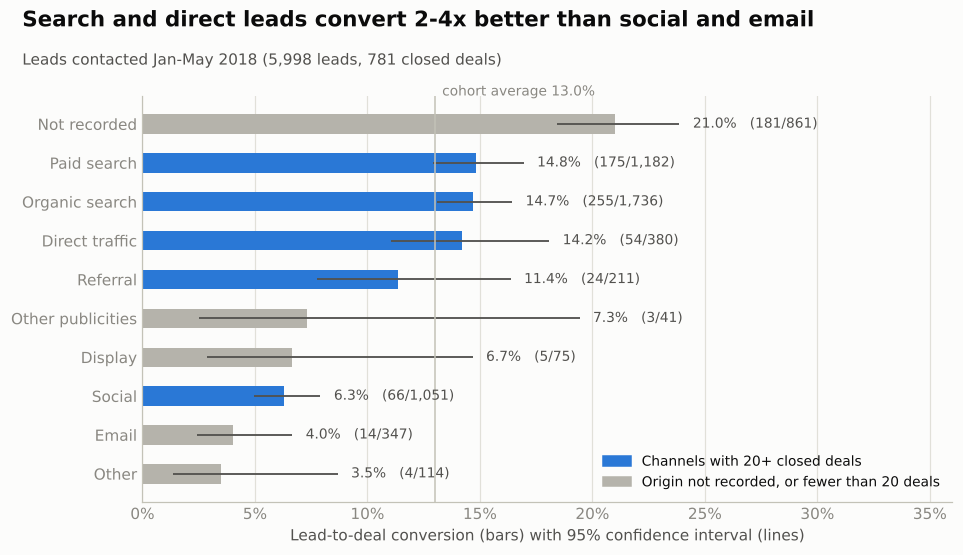

,channel,leads,won,conv,lo,hi,median_days_to_close
7,Organic search,1736,255,14.70,13.10,16.40,13.00
8,Paid search,1182,175,14.80,12.90,16.90,13.00
2,Social,1051,66,6.30,5.00,7.90,23.00
9,Not recorded,861,181,21.00,18.40,23.90,9.00
6,Direct traffic,380,54,14.20,11.10,18.10,9.50
1,Email,347,14,4.00,2.40,6.70,19.50
5,Referral,211,24,11.40,7.80,16.40,18.50
0,Other,114,4,3.50,1.40,8.70,9.00
3,Display,75,5,6.70,2.90,14.70,10.00
4,Other publicities,41,3,7.30,2.50,19.40,35.00


In [2]:
ch = sql("q1_channel_conversion")
ci = [wilson(k, n) for k, n in zip(ch["won"], ch["leads"])]
ch["conv"] = ch["won"] / ch["leads"] * 100
ch["lo"] = [c[0] * 100 for c in ci]
ch["hi"] = [c[1] * 100 for c in ci]
nice = {"organic_search": "Organic search", "paid_search": "Paid search", "social": "Social",
        "unknown": "Not recorded", "direct_traffic": "Direct traffic", "email": "Email",
        "referral": "Referral", "other": "Other", "display": "Display",
        "other_publicities": "Other publicities"}
ch["channel"] = ch["origin"].map(nice)
grey = (ch["origin"] == "unknown") | (ch["won"] < 20)
overall = ch["won"].sum() / ch["leads"].sum() * 100
ch = ch.assign(grey=grey).sort_values("conv").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(9.5, 5.2))
y = np.arange(len(ch))
ax.barh(y, ch["conv"], height=0.5, color=[GREY if g else C[0] for g in ch["grey"]])
ax.hlines(y, ch["lo"], ch["hi"], color=INK2, linewidth=1.2)
for yi, r in zip(y, ch.itertuples()):
    ax.text(r.hi + 0.6, yi, f"{r.conv:.1f}%   ({r.won}/{r.leads:,})", va="center", fontsize=9, color=INK2)
ax.axvline(overall, color=AXIS, linewidth=1)
ax.text(overall + 0.3, len(ch) - 0.35, f"cohort average {overall:.1f}%", fontsize=9, color=MUTED, va="bottom")
ax.set_yticks(y, ch["channel"])
ax.set_xlim(0, 36)
ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.set_xlabel("Lead-to-deal conversion (bars) with 95% confidence interval (lines)")
style(ax, grid="x")
ax.legend(handles=[Patch(color=C[0], label="Channels with 20+ closed deals"),
                   Patch(color=GREY, label="Origin not recorded, or fewer than 20 deals")],
          loc="lower right", frameon=False, fontsize=9)
headline(fig, "Search and direct leads convert 2-4x better than social and email",
         f"Leads contacted Jan-May 2018 ({ch['leads'].sum():,} leads, {ch['won'].sum()} closed deals)")
fig.subplots_adjust(top=0.82)
save(fig, "01_channel_conversion")
plt.show()

ch[["channel", "leads", "won", "conv", "lo", "hi", "median_days_to_close"]].sort_values("leads", ascending=False).round(1)

**Reading.** Paid search (14.8%), organic search (14.7%) and direct traffic (14.2%) are statistically indistinguishable from each other and well above social (6.3%) and email (4.0%), whose intervals do not overlap them. Social is the third-largest source of leads, after the two search channels, yet it closes less than half as often, and that gap is not explained by one weak landing page (checked in A3). Channels with fewer than 20 deals are shown in grey: their intervals are too wide to rank.

"Not recorded" has the highest rate (21%), but it is a mix of unknown sources, so I do not draw conclusions from it. It is also a data-quality finding: 14% of leads have no tracked origin.

## A2. How much of the revenue from recruited sellers depends on a few of them?

Conversion is a funnel metric. The business cares about what recruited sellers sell afterwards. `q7_revenue_concentration` ranks the sellers that made at least one delivered sale.

357 recruited sellers with delivered sales | total GMV R$ 644,569
mean per seller R$ 1,806 | median R$ 538
top 1 seller = 17.4% | top 5 = 35.9% | top 10% (36) = 65.6%


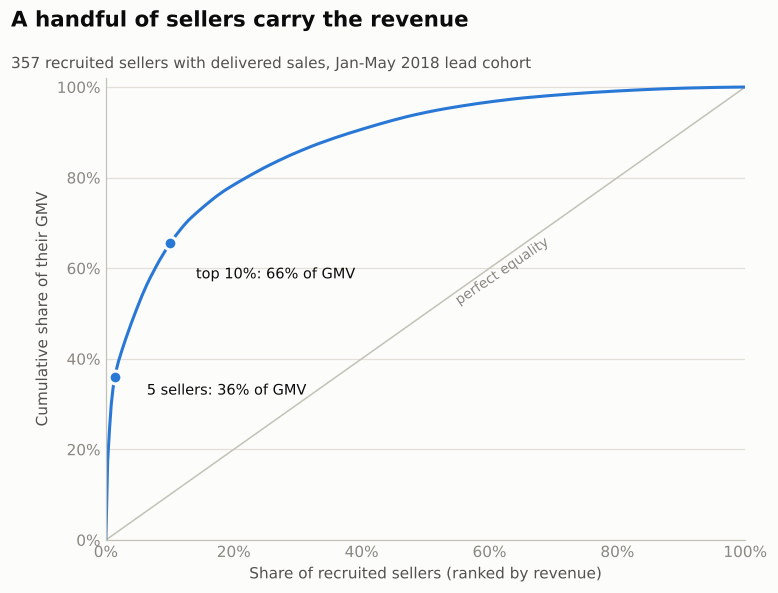

,seller_rank,origin,business_segment,revenue,pct_of_total,cum_pct,milestone
0,1,unknown,watches,"112,436.00",17.40,17.40,
1,2,organic_search,small_appliances,"44,213.00",6.90,24.30,
2,3,paid_search,health_beauty,"36,289.00",5.60,29.90,
3,4,organic_search,home_appliances,"23,065.00",3.60,33.50,
4,5,organic_search,pet,"15,633.00",2.40,35.90,
5,6,social,pet,"12,078.00",1.90,37.80,


In [3]:
rev = pd.read_sql_query(
    "SELECT seller_revenue AS revenue FROM v_funnel_cohort WHERE seller_revenue > 0 "
    "ORDER BY seller_revenue DESC", con)["revenue"].to_numpy()
n = len(rev)
cum = np.cumsum(rev) / rev.sum()
x = np.arange(1, n + 1) / n
k10 = int(round(0.10 * n))
print(f"{n} recruited sellers with delivered sales | total GMV R$ {rev.sum():,.0f}")
print(f"mean per seller R$ {rev.mean():,.0f} | median R$ {np.median(rev):,.0f}")
print(f"top 1 seller = {rev[0] / rev.sum():.1%} | top 5 = {cum[4]:.1%} | top 10% ({k10}) = {cum[k10 - 1]:.1%}")

fig, ax = plt.subplots(figsize=(7.5, 5.6))
ax.plot([0, 1], [0, 1], color=AXIS, linewidth=1)
ax.plot(np.r_[0, x], np.r_[0, cum], color=C[0], linewidth=2)
pts = [(5 / n, cum[4], f"5 sellers: {cum[4]:.0%} of GMV", (0.05, -0.03)),
       (k10 / n, cum[k10 - 1], f"top 10%: {cum[k10 - 1]:.0%} of GMV", (0.04, -0.07))]
for px, py, label, (dx, dy) in pts:
    ax.scatter([px], [py], s=70, color=C[0], edgecolor=SURFACE, linewidth=2, zorder=3)
    ax.text(px + dx, py + dy, label, fontsize=9.5, color=INK, va="center")
ax.text(0.62, 0.52, "perfect equality", fontsize=9, color=MUTED, rotation=34, ha="center")
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlabel("Share of recruited sellers (ranked by revenue)")
ax.set_ylabel("Cumulative share of their GMV")
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
style(ax, grid="y")
headline(fig, "A handful of sellers carry the revenue",
         f"{n} recruited sellers with delivered sales, Jan-May 2018 lead cohort")
fig.subplots_adjust(top=0.86)
save(fig, "02_seller_concentration")
plt.show()

sql("q7_revenue_concentration").head(6)

**Reading.** The top 5 sellers produce about 36% of the GMV and the median seller sells only R$ 538 against a mean of R$ 1,806. One watch seller alone accounts for 17.4%. This matters for the channel decision:

- The "Not recorded" channel looks like the most valuable per lead (R$ 241 vs R$ 117 for paid search), but **without that single seller it drops to R$ 110**. Revenue per lead is too volatile to rank channels.
- Conversion rate, which is stable and tested, is the metric I would steer by. Seller revenue is better used as a risk indicator.
- Also, only 357 of the 781 recruited sellers made a delivered sale, so activation (about 45% of deals) is a second place to look for value.

## A3. Does the landing page matter beyond the channel?

Landing pages are partly confounded with channel (one page receives 94% social traffic, another 72% "not recorded"). So the comparison is made **within** a channel.

In [4]:
lp = pd.read_sql_query("""
    SELECT origin,
           CASE WHEN landing_page_id LIKE '22c29808%' OR landing_page_id LIKE 'b76ef374%'
                THEN 'two best pages' ELSE 'all other pages' END AS landing_group,
           COUNT(*) AS leads, SUM(is_won) AS won
    FROM v_funnel_cohort
    WHERE origin IN ('organic_search', 'paid_search')
    GROUP BY 1, 2 ORDER BY 1, 2
""", con)
lp["conv_pct"] = lp["won"] / lp["leads"] * 100
lp[["lo", "hi"]] = [[v * 100 for v in wilson(k, n)] for k, n in zip(lp["won"], lp["leads"])]
lp.round(1)

,origin,landing_group,leads,won,conv_pct,lo,hi
0,organic_search,all other pages,1220,126,10.30,8.70,12.20
1,organic_search,two best pages,516,129,25.00,21.50,28.90
2,paid_search,all other pages,1006,148,14.70,12.70,17.00
3,paid_search,two best pages,176,27,15.30,10.80,21.40


**Reading.** Inside **organic search**, leads that land on the two best pages convert at about **25%** versus about **10%** on all other pages (non-overlapping intervals). Inside paid search there is no difference. Social stays weak on every page (7.2% on other pages, 5.2% on the page that concentrates its traffic), so the social gap is a real channel effect. The landing-page finding is a concrete, cheap experiment: send more organic traffic to the pages that work. It is observational, so it should be A/B tested before being trusted as a cause.

# Part B. Customers and satisfaction

All of Part B uses delivered orders (`v_orders_delivered`, 96,470 orders).

## B1. What does a late delivery cost in reviews?

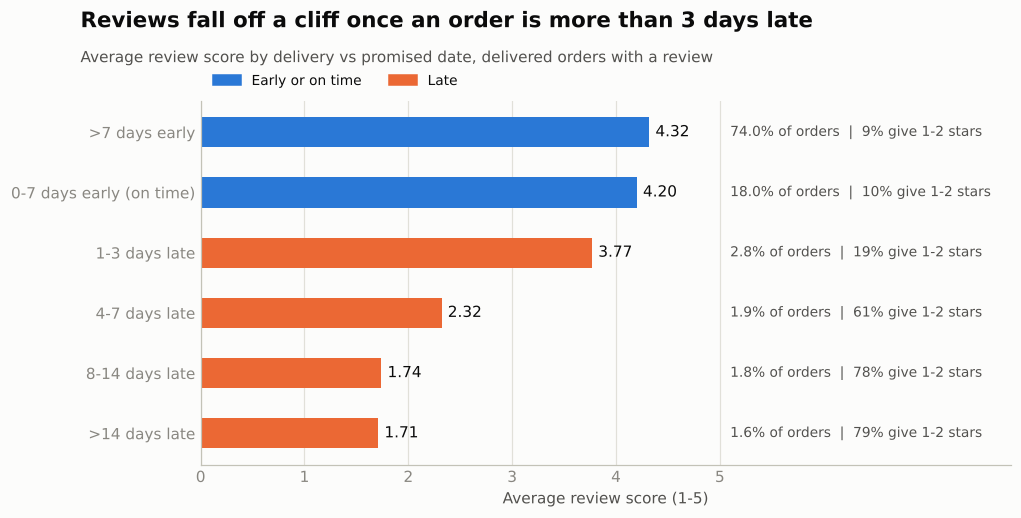

Late orders: 8.0% of orders, but 33.8% of all 1-2 star reviews


In [5]:
d = sql("q2_delay_vs_review").copy()
d["label"] = d["bucket"].str.slice(3).str.capitalize()
late_flag = d["bucket"].str[0].isin(list("cdef"))

fig, ax = plt.subplots(figsize=(9.5, 4.8))
y = np.arange(len(d))[::-1]
ax.barh(y, d["avg_score"], height=0.5, color=[C[1] if f else C[0] for f in late_flag])
for yi, r in zip(y, d.itertuples()):
    ax.text(r.avg_score + 0.06, yi, f"{r.avg_score:.2f}", va="center", fontsize=10, color=INK)
    ax.text(5.1, yi, f"{r.pct_orders:.1f}% of orders  |  {r.pct_1_2_stars:.0f}% give 1-2 stars",
            va="center", ha="left", fontsize=9, color=INK2)
ax.set_yticks(y, d["label"])
ax.set_xlim(0, 7.8); ax.set_xticks([0, 1, 2, 3, 4, 5])
ax.set_xlabel("Average review score (1-5)")
style(ax, grid="x")
ax.legend(handles=[Patch(color=C[0], label="Early or on time"), Patch(color=C[1], label="Late")],
          loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, frameon=False, fontsize=9)
headline(fig, "Reviews fall off a cliff once an order is more than 3 days late",
         "Average review score by delivery vs promised date, delivered orders with a review")
fig.subplots_adjust(top=0.80)
save(fig, "03_delay_vs_review")
plt.show()

r = pd.read_sql_query("""SELECT COUNT(*) AS n, SUM(is_late) AS late, SUM(review_score <= 2) AS detr,
                                SUM(is_late = 1 AND review_score <= 2) AS late_detr
                         FROM v_orders_delivered WHERE review_score IS NOT NULL""", con).iloc[0]
print(f"Late orders: {r.late / r.n:.1%} of orders, but {r.late_detr / r.detr:.1%} of all 1-2 star reviews")

**Reading.** One to three days late already costs about 0.4 points (3.77 vs 4.20 on time), but from 4 days late the score collapses to 2.3 and then below 1.8. The 8% of orders that arrive late generate about a third of all negative reviews. A second finding sits at the top: **74% of orders arrive more than 7 days before the promised date**, so the delivery estimate is very conservative.

A natural objection is that late orders go to hard regions or categories. They do not explain it: within each of the top six states and each of the top five categories, orders 4+ days late score 1.7-2.3 against 4.0-4.3 for the rest (checked during exploration).

## B2. Where is the logistics problem?

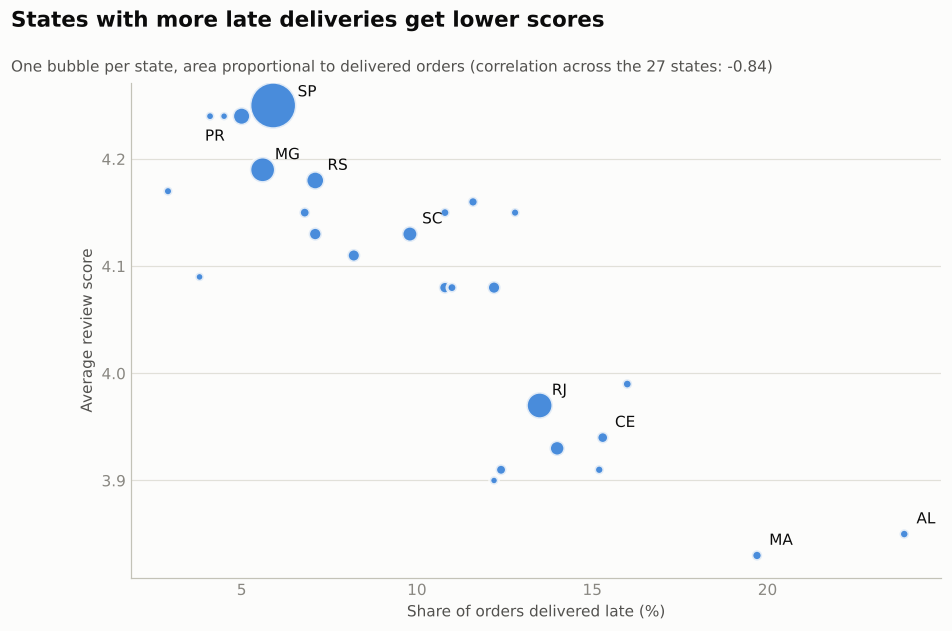

correlation late% vs score across 27 states: -0.84
SP + RJ + MG = 63% of GMV


,customer_state,orders,pct_gmv,freight_pct_of_price,avg_delivery_days,late_pct,avg_score
0,SP,40494,38.30,13.90,8.80,5.90,4.20
1,RJ,12350,13.30,16.80,15.30,13.50,4.00
2,MG,11354,11.70,17.20,12.00,5.60,4.20
3,RS,5344,5.50,18.20,15.30,7.10,4.20
4,PR,4923,5.00,17.40,12.00,5.00,4.20
5,SC,3546,3.80,17.40,15.00,9.80,4.10
6,BA,3256,3.70,19.80,19.30,14.00,3.90
7,DF,2080,2.20,16.70,13.00,7.10,4.10
8,GO,1957,2.10,18.20,15.60,8.20,4.10
9,ES,1995,2.00,18.20,15.80,12.20,4.10


In [6]:
st = sql("q3_state_performance")
fig, ax = plt.subplots(figsize=(9.5, 6))
sizes = 30 + 900 * st["orders"] / st["orders"].max()
ax.scatter(st["late_pct"], st["avg_score"], s=sizes, color=C[0], alpha=0.85, edgecolor=SURFACE, linewidth=2)
show = set(st.nlargest(6, "orders")["customer_state"]) | {"MA", "AL", "CE"}
offsets = {"PR": (-24, -16), "SP": (16, 6)}            # keep labels off neighbouring bubbles
for r in st.itertuples():
    if r.customer_state in show:
        ax.annotate(r.customer_state, (r.late_pct, r.avg_score),
                    xytext=offsets.get(r.customer_state, (8, 7)),
                    textcoords="offset points", fontsize=10, color=INK)
ax.set_xlabel("Share of orders delivered late (%)")
ax.set_ylabel("Average review score")
style(ax, grid="y")
headline(fig, "States with more late deliveries get lower scores",
         "One bubble per state, area proportional to delivered orders (correlation across the 27 states: -0.84)")
fig.subplots_adjust(top=0.86)
save(fig, "04_states_late_vs_score")
plt.show()

print("correlation late% vs score across 27 states:", round(np.corrcoef(st["late_pct"], st["avg_score"])[0, 1], 2))
print(f"SP + RJ + MG = {st.nlargest(3, 'orders')['pct_gmv'].sum():.0f}% of GMV")
st[["customer_state", "orders", "pct_gmv", "freight_pct_of_price", "avg_delivery_days",
    "late_pct", "avg_score"]].head(10).round(1)

**Reading.** São Paulo, Rio and Minas Gerais are 63% of the GMV. **Rio is the weak link inside the core market**: 13.5% of its orders are late (São Paulo 5.9%) and its score is 3.97, the lowest of the six biggest states. The Northeast (BA, CE, MA, AL) has 14-24% late orders, scores of 3.8-3.9 and shipping costs of 19-26% of the price, against 13.9% in São Paulo. Across the 27 states, late share and review score are strongly related (correlation -0.84).

## B3. How did sales evolve?

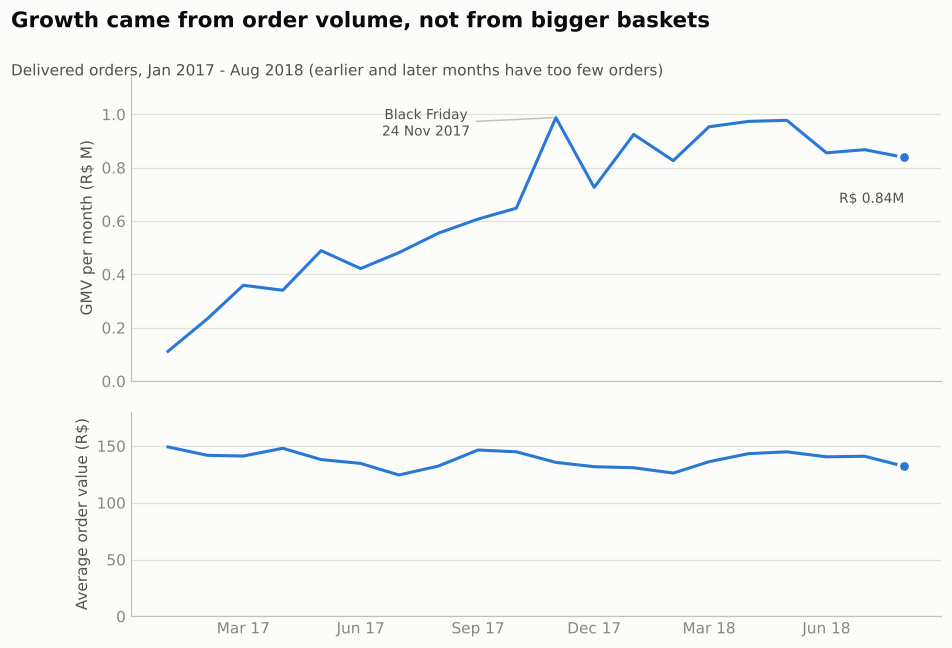

In [7]:
m = sql("q1_monthly_overview")
m["month"] = pd.to_datetime(m["purchase_month"] + "-01")

fig, (a1, a2) = plt.subplots(2, 1, figsize=(9.5, 6.4), sharex=True,
                              gridspec_kw={"height_ratios": [1.5, 1]})
a1.plot(m["month"], m["gmv"] / 1e6, color=C[0], linewidth=2)
a1.scatter(m["month"].iloc[-1], m["gmv"].iloc[-1] / 1e6, s=60, color=C[0], edgecolor=SURFACE, linewidth=2, zorder=3)
bf = m.loc[m["purchase_month"] == "2017-11"].iloc[0]
a1.annotate("Black Friday\n24 Nov 2017", (bf["month"], bf["gmv"] / 1e6), xytext=(-85, -4),
            textcoords="offset points", fontsize=9, color=INK2, ha="center", va="center",
            arrowprops=dict(arrowstyle="-", color=AXIS, linewidth=1))
a1.text(m["month"].iloc[-1], m["gmv"].iloc[-1] / 1e6 - 0.17, f"R$ {m['gmv'].iloc[-1] / 1e6:.2f}M", ha="right", fontsize=9, color=INK2)
a1.set_ylim(0, 1.15); a1.set_ylabel("GMV per month (R$ M)")
style(a1, grid="y")
a2.plot(m["month"], m["aov"], color=C[0], linewidth=2)
a2.scatter(m["month"].iloc[-1], m["aov"].iloc[-1], s=60, color=C[0], edgecolor=SURFACE, linewidth=2, zorder=3)
a2.set_ylim(0, 180); a2.set_ylabel("Average order value (R$)")
style(a2, grid="y")
a2.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b %y"))
a2.xaxis.set_major_locator(plt.matplotlib.dates.MonthLocator(interval=3))
headline(fig, "Growth came from order volume, not from bigger baskets",
         "Delivered orders, Jan 2017 - Aug 2018 (earlier and later months have too few orders)")
fig.subplots_adjust(top=0.88, hspace=0.12)
save(fig, "05_monthly_trend")
plt.show()

**Reading.** Monthly GMV grew from R$ 0.11M in January 2017 to R$ 0.73M in December 2017, peaking at R$ 0.99M in the Black Friday month, and then **plateaued at R$ 0.83-0.98M a month from January 2018**, with a slight dip over the summer. The average order value stayed in a R$ 125-150 band throughout, so growth was entirely volume, and volume has stopped growing. Black Friday 2017 produced 1,147 orders on a single day, roughly five times the daily average of the rest of that month.

## B4. Does a bad first experience stop people coming back?

97% of customers buy once, so repeat purchase is the retention lever that matters most. `q7_first_experience_vs_repeat` follows first orders placed Jan 2017 - Feb 2018 for 180 days (so each has at least 180 days of observation).

  segment  customers  pct_customers           gmv  pct_gmv  avg_spend  avg_score
  1 order      90549          97.00 12,491,840.00    94.50     138.00       4.15
2+ orders       2801           3.00    728,409.00     5.50     260.10       4.20


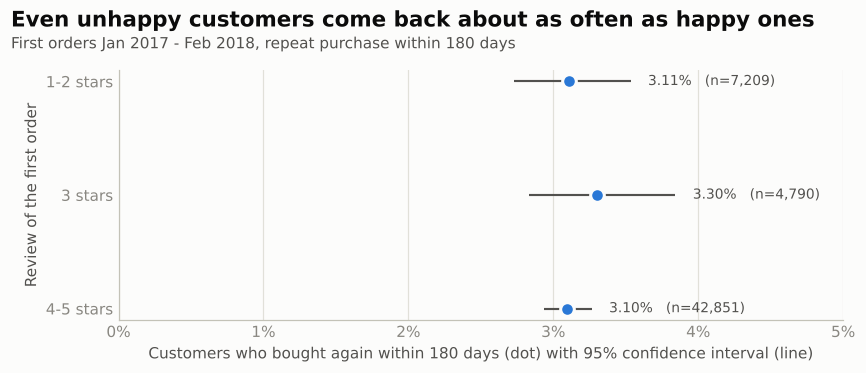

1-2 stars vs 4-5 stars: difference +0.01 pp (95% CI -0.42 to +0.44), two-sided p = 0.96


In [8]:
print(sql("q5_repeat_vs_one_time").to_string(index=False))

f7 = sql("q7_first_experience_vs_repeat")
f7 = f7[f7["first_review"] != "no review"]                    # 'no review': too few orders
g = f7.groupby("first_review")[["first_orders", "repeated_180d"]].sum()
order = ["1-2 stars", "3 stars", "4-5 stars"]
g = g.loc[order]
g["rate"] = g["repeated_180d"] / g["first_orders"] * 100
g[["lo", "hi"]] = [[v * 100 for v in wilson(k, n)] for k, n in zip(g["repeated_180d"], g["first_orders"])]

fig, ax = plt.subplots(figsize=(8.5, 3.2))
y = np.arange(len(g))[::-1]
ax.hlines(y, g["lo"], g["hi"], color=INK2, linewidth=1.4)
ax.scatter(g["rate"], y, s=80, color=C[0], edgecolor=SURFACE, linewidth=2, zorder=3)
for yi, r in zip(y, g.itertuples()):
    ax.text(r.hi + 0.12, yi, f"{r.rate:.2f}%   (n={r.first_orders:,})", va="center", fontsize=9, color=INK2)
ax.set_yticks(y, list(g.index))
ax.set_xlim(0, 5); ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.set_xlabel("Customers who bought again within 180 days (dot) with 95% confidence interval (line)")
ax.set_ylabel("Review of the first order")
style(ax, grid="x")
headline(fig, "Even unhappy customers come back about as often as happy ones",
         "First orders Jan 2017 - Feb 2018, repeat purchase within 180 days", top=0.99)
fig.subplots_adjust(top=0.82)
save(fig, "06_repeat_by_first_review")
plt.show()

bad, good = g.loc["1-2 stars"], g.loc["4-5 stars"]
p1, p2 = bad["repeated_180d"] / bad["first_orders"], good["repeated_180d"] / good["first_orders"]
pool = (bad["repeated_180d"] + good["repeated_180d"]) / (bad["first_orders"] + good["first_orders"])
se = math.sqrt(pool * (1 - pool) * (1 / bad["first_orders"] + 1 / good["first_orders"]))
z = (p1 - p2) / se
se_d = math.sqrt(p1 * (1 - p1) / bad["first_orders"] + p2 * (1 - p2) / good["first_orders"])
print(f"1-2 stars vs 4-5 stars: difference {100 * (p1 - p2):+.2f} pp "
      f"(95% CI {100 * (p1 - p2 - 1.96 * se_d):+.2f} to {100 * (p1 - p2 + 1.96 * se_d):+.2f}), "
      f"two-sided p = {2 * stats.norm.sf(abs(z)):.2f}")

**Reading.** Customers who gave 1-2 stars repeat at about the same rate as those who gave 4-5 stars: the difference is statistically zero, and the interval rules out anything large. Repeat purchase is structurally low (about 3%) **regardless of satisfaction**. Satisfaction still matters for reputation and for the review score customers see, but this data gives no evidence that fixing it would build retention. A retention programme would need its own test.

Limit: this only sees purchases on Olist. A customer who goes elsewhere is invisible.

# Part C. Customer segmentation

Because 97% of customers buy once, classic RFM (frequency) segmentation carries no information. I segment on what actually varies between customers: **how much they spent, how long delivery took and how they rated it**, using K-means on standardised features (spend and delivery time on a log scale).

In [9]:
cust = pd.read_sql_query("""
    SELECT customer_unique_id,
           SUM(items_value)   AS spend,
           AVG(delivery_days) AS delivery_days,
           AVG(review_score)  AS score,
           AVG(is_late)       AS late_share
    FROM v_orders_delivered
    WHERE review_score IS NOT NULL
    GROUP BY customer_unique_id
""", con)
X = StandardScaler().fit_transform(
    np.column_stack([np.log1p(cust["spend"]), np.log1p(cust["delivery_days"]), cust["score"]]))

rows = []
for k in range(2, 7):
    lab = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X)
    rows.append((k, silhouette_score(X, lab, sample_size=15000, random_state=42)))
sil = pd.DataFrame(rows, columns=["k", "silhouette"])
print(sil.round(3).to_string(index=False))

 k  silhouette
 2        0.39
 3        0.28
 4        0.27
 5        0.26
 6        0.26


Silhouette is highest at k = 2, which is a trivial "satisfied vs unsatisfied" split. For targeting I need more than two groups, so I choose the best k between 3 and 4 (the chart palette is validated for four categories).

In [10]:
K = int(sil[sil["k"].between(3, 4)].sort_values("silhouette", ascending=False).iloc[0]["k"])
cust["cluster"] = KMeans(n_clusters=K, n_init=10, random_state=42).fit_predict(X)
prof = (cust.groupby("cluster")
        .agg(customers=("spend", "size"), median_spend=("spend", "median"),
             median_delivery_days=("delivery_days", "median"), avg_score=("score", "mean"),
             late_pct=("late_share", lambda s: s.mean() * 100))
        .assign(pct_customers=lambda t: t["customers"] / t["customers"].sum() * 100,
                pct_gmv=lambda t: cust.groupby("cluster")["spend"].sum() / cust["spend"].sum() * 100))
prof["no_late_order_pct"] = cust.groupby("cluster")["late_share"].apply(lambda s: (s == 0).mean() * 100)

# name the segments from their profile (deterministic: random_state is fixed)
unhappy = prof["avg_score"].idxmin()
big = prof.drop(unhappy)["median_spend"].idxmax()
small = [c for c in prof.index if c not in (unhappy, big)]
seg_order = [big, unhappy] + small
seg_names = {big: "Big baskets", unhappy: "Unhappy", **{c: "Small baskets" for c in small}} if K == 3 \
    else {c: f"Segment {c}" for c in prof.index}
if K != 3:
    seg_order = list(prof.index)
print("chosen k =", K)
prof.rename(index=seg_names).loc[[seg_names[c] for c in seg_order]].round(1)

chosen k = 3


,customers,median_spend,median_delivery_days,avg_score,late_pct,pct_customers,pct_gmv,no_late_order_pct
cluster,,,,,,,,
Big baskets,37933,150.00,12.00,4.70,4.90,40.90,66.70,94.90
Unhappy,15562,97.90,17.00,1.70,31.00,16.80,17.70,68.50
Small baskets,39252,46.90,7.40,4.60,2.00,42.30,15.60,98.00


**Reading.** The three segments separate cleanly on spend and experience:

- **Big baskets** (41% of customers, 67% of GMV): median spend R$ 150, happy (4.66), delivery takes 12 days.
- **Small baskets** (42% of customers, 16% of GMV): median spend R$ 47, fastest delivery (7 days), happy (4.64).
- **Unhappy** (17% of customers, 18% of GMV): average score 1.7, delivery takes 17 days. **Only about 30% of them had a late order**, so roughly 70% are unhappy with an on-time delivery. That points to product or seller quality, not logistics alone, and matches the weak scores of some categories (bed, bath and table; office furniture).

The unhappy segment is not a low-value niche: it holds almost a fifth of the GMV. Because repeat purchase does not depend on satisfaction (B4), the case for fixing it is reputation and marketplace health, not retention.

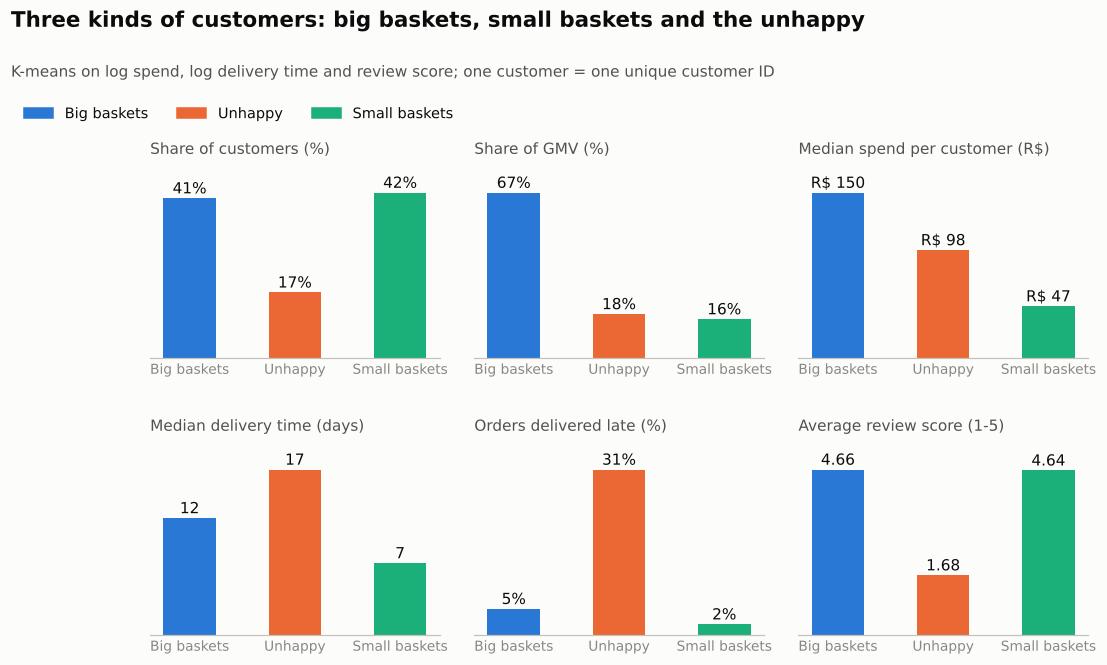

In [11]:
metrics = [("pct_customers", "Share of customers (%)", "{:.0f}%"),
           ("pct_gmv", "Share of GMV (%)", "{:.0f}%"),
           ("median_spend", "Median spend per customer (R$)", "R$ {:.0f}"),
           ("median_delivery_days", "Median delivery time (days)", "{:.0f}"),
           ("late_pct", "Orders delivered late (%)", "{:.0f}%"),
           ("avg_score", "Average review score (1-5)", "{:.2f}")]
colors = C[: len(seg_order)]
labels = [seg_names[c] for c in seg_order]

fig, axes = plt.subplots(2, 3, figsize=(11, 6.6))
for ax, (col, title, fmt) in zip(axes.ravel(), metrics):
    vals = [prof.loc[c, col] for c in seg_order]
    ax.bar(range(len(vals)), vals, width=0.5, color=colors)
    for i, v in enumerate(vals):
        ax.text(i, v + max(vals) * 0.03, fmt.format(v), ha="center", fontsize=10, color=INK)
    ax.set_xticks(range(len(vals)), labels, fontsize=9)
    ax.set_yticks([]); ax.spines["left"].set_visible(False)
    ax.set_ylim(0, max(vals) * 1.18)
    ax.set_title(title, loc="left", fontsize=10, color=INK2)
    style(ax)
headline(fig, "Three kinds of customers: big baskets, small baskets and the unhappy",
         "K-means on log spend, log delivery time and review score; one customer = one unique customer ID")
fig.legend(handles=[Patch(color=c, label=l) for c, l in zip(colors, labels)],
           loc="upper left", bbox_to_anchor=(0.01, 0.855), ncol=3, frameon=False, fontsize=9.5)
fig.subplots_adjust(top=0.76, hspace=0.42, wspace=0.12)
save(fig, "07_customer_segments")
plt.show()

# Recommendations

1. **Steer lead generation by conversion, and rebalance towards search.** Paid and organic search convert about 15% against 6% for social and 4% for email, and those gaps are statistically clear. Review the social and email spend or process before adding budget. Do not steer by revenue per lead: it is dominated by one seller.
2. **Run an A/B test on organic landing pages.** The two best pages convert 25% vs 10% for other organic leads. Replicating them is the cheapest experiment in the data.
3. **Treat seller revenue as a concentration risk.** Five sellers produce 36% of the recruited-seller GMV. Account management for the top sellers, and activating the more than half of closed deals that never make a delivered sale, are both worth more than one more percentage point of conversion.
4. **Fix late deliveries beyond 3 days, starting in Rio and the Northeast.** That is where reviews collapse, and late orders are a third of all negative reviews. The other two thirds are not logistics (see Part C), so delivery alone will not close the satisfaction gap. Delivery estimates are padded (74% of orders arrive more than a week early), so there is room to tighten them realistically while managing the late tail separately.
5. **Do not expect satisfaction work to deliver retention on its own.** Repeat purchase is about 3% even among happy customers. Retention needs its own hypotheses (CRM, re-engagement, cross-marketplace behaviour) and its own test.
6. **Fix attribution.** 14% of leads have no recorded origin, and that is the best-converting bucket, so the channel picture is incomplete.

# Limitations

- **Observational data, 2016-2018.** Findings describe associations, not proven causes; the landing-page effect and the delay effect should be tested experimentally.
- **GMV is not revenue.** Olist's income depends on commissions and fees that are not in the data.
- **Funnel selection.** Only leads contacted Jan-May 2018 are compared, because closed deals before Dec 2017 are missing.
- **Small channels.** Display, other and other publicities have fewer than 20 deals and cannot be ranked.
- **Single marketplace view.** Repeat behaviour on other platforms is invisible.
- **Segmentation is descriptive.** K-means groups depend on the chosen features and scaling.